# Life Expectancy (WHO) — Part 2: Model Training & Evaluation

In [1]:
# Core imports (same as Part 1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

# Load state produced at the end of Part 1 — exact objects, not recomputed
import pickle

with open('life_expectancy_split_state.pkl', 'rb') as f:
    state = pickle.load(f)

X_train = state['X_train']
X_test = state['X_test']
X_train_scaled = state['X_train_scaled']
X_test_scaled = state['X_test_scaled']
y_train = state['y_train']
y_test = state['y_test']

print('Loaded from Part 1:')
print(f'  X_train: {X_train.shape}  X_test: {X_test.shape}')
print(f'  X_train_scaled: {X_train_scaled.shape}  X_test_scaled: {X_test_scaled.shape}')

Loaded from Part 1:
  X_train: (2342, 15)  X_test: (586, 15)
  X_train_scaled: (2342, 15)  X_test_scaled: (586, 15)


## Step 5 — OLS Model: Manual Matrix Formulation vs Statsmodels

### 5.1 Manual OLS via the Normal Equation

In [2]:
# Design matrix: add intercept column of 1s
X_train_mat = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled.values])
Y_train_vec = y_train.values

# Normal equation: beta_hat = (X^T X)^-1 X^T Y
XtX = X_train_mat.T @ X_train_mat
XtY = X_train_mat.T @ Y_train_vec
beta_hat = np.linalg.inv(XtX) @ XtY

feature_names = ['beta_0 (intercept)'] + [f'beta_{i+1} ({c})' for i, c in enumerate(X_train_scaled.columns)]
manual_coefs = pd.Series(beta_hat, index=feature_names)
manual_coefs

beta_0 (intercept)                      69.149018
beta_1 (Year)                           -0.085138
beta_2 (Status)                          0.730666
beta_3 (Alcohol)                        -0.216765
beta_4 (Hepatitis B)                    -0.498894
beta_5 (Measles)                        -0.251773
beta_6 (BMI)                             0.971801
beta_7 (Polio)                           0.941372
beta_8 (Total expenditure)               0.032260
beta_9 (Diphtheria)                      1.222741
beta_10 (HIV/AIDS)                      -3.607053
beta_11 (thinness  1-19 years)          -0.518324
beta_12 (Schooling)                      3.507916
beta_13 (log_GDP)                        1.040867
beta_14 (log_percentage expenditure)     0.484935
beta_15 (log_Population)                -0.395406
dtype: float64

### 5.2 Statsmodels Verification

In [3]:
X_train_sm = sm.add_constant(X_train_scaled)
ols_model = sm.OLS(y_train, X_train_sm).fit()

# Side-by-side comparison: manual NumPy beta vs statsmodels params
comparison = pd.DataFrame({
    'Manual_NumPy_Beta': beta_hat,
    'Statsmodels_Param': ols_model.params.values
}, index=['Intercept'] + list(X_train_scaled.columns))
comparison['Abs_Diff'] = (comparison['Manual_NumPy_Beta'] - comparison['Statsmodels_Param']).abs().round(3)
comparison

,Manual_NumPy_Beta,Statsmodels_Param,Abs_Diff
Intercept,69.149018,69.149018,0.0
Year,-0.085138,-0.085138,0.0
Status,0.730666,0.730666,0.0
Alcohol,-0.216765,-0.216765,0.0
Hepatitis B,-0.498894,-0.498894,0.0
Measles,-0.251773,-0.251773,0.0
BMI,0.971801,0.971801,0.0
Polio,0.941372,0.941372,0.0
Total expenditure,0.032260,0.032260,0.0
Diphtheria,1.222741,1.222741,0.0


In [4]:
print(f"Max absolute difference: {comparison['Abs_Diff'].max():.10f}")
print("Manual normal-equation coefficients match statsmodels exactly (up to floating-point precision).")

Max absolute difference: 0.0000000000
Manual normal-equation coefficients match statsmodels exactly (up to floating-point precision).


In [5]:
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.771
Method:                 Least Squares   F-statistic:                     526.9
Date:                Sat, 22 Aug 2026   Prob (F-statistic):               0.00
Time:                        12:11:57   Log-Likelihood:                -6879.7
No. Observations:                2342   AIC:                         1.379e+04
Df Residuals:                    2326   BIC:                         1.388e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

## Step 6 — Prediction, Performance & Residual Diagnostics

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 6.1 Predictions
y_train_pred = ols_model.predict(X_train_sm)
X_test_sm = sm.add_constant(X_test_scaled, has_constant='add')
y_test_pred = ols_model.predict(X_test_sm)

In [7]:
# 6.2 Performance metrics
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

n_train, p = X_train_scaled.shape

metrics_table = pd.DataFrame({
    'Metric': ['R2', 'Adjusted R2', 'RMSE', 'MAE'],
    'Train': [
        r2_score(y_train, y_train_pred),
        adjusted_r2(r2_score(y_train, y_train_pred), n_train, p),
        mean_squared_error(y_train, y_train_pred) ** 0.5,
        mean_absolute_error(y_train, y_train_pred)
    ],
    'Test': [
        r2_score(y_test, y_test_pred),
        adjusted_r2(r2_score(y_test, y_test_pred), len(y_test), p),
        mean_squared_error(y_test, y_test_pred) ** 0.5,
        mean_absolute_error(y_test, y_test_pred)
    ]
})
metrics_table.round(4)

,Metric,Train,Test
0,R2,0.7726,0.7823
1,Adjusted R2,0.7712,0.7765
2,RMSE,4.5659,4.3397
3,MAE,3.4926,3.3544


### 6.3 Prediction Plots

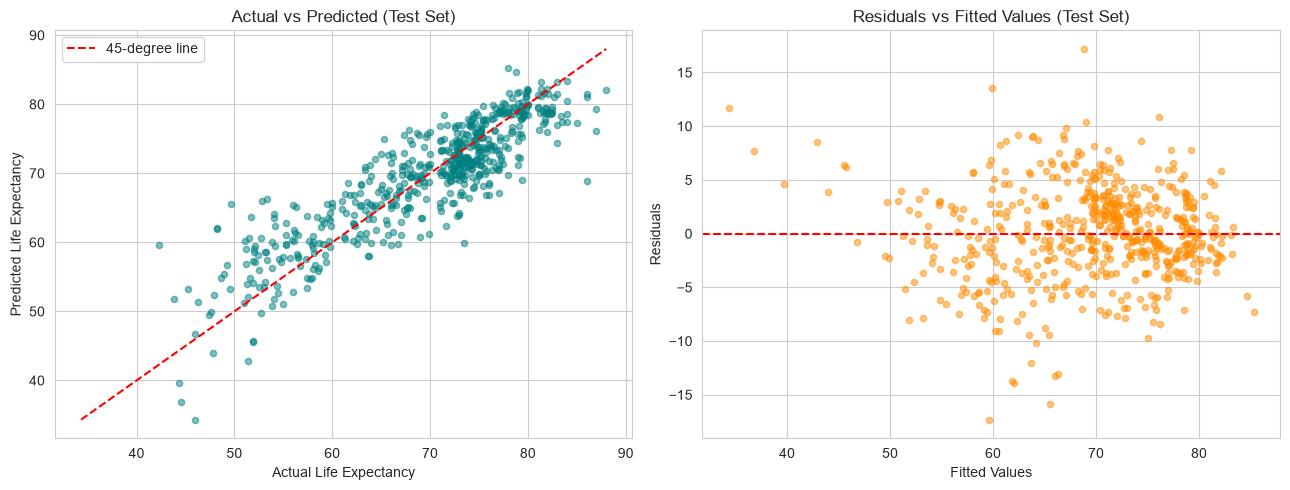

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_test_pred, alpha=0.5, s=20, color='teal')
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
axes[0].plot(lims, lims, 'r--', label='45-degree line')
axes[0].set_xlabel('Actual Life Expectancy')
axes[0].set_ylabel('Predicted Life Expectancy')
axes[0].set_title('Actual vs Predicted (Test Set)')
axes[0].legend()

residuals_test = y_test.values - y_test_pred.values
axes[1].scatter(y_test_pred, residuals_test, alpha=0.5, s=20, color='darkorange')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Fitted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residuals vs Fitted Values (Test Set)')

plt.tight_layout()
plt.show()

### 6.4 Residual Normality Tests

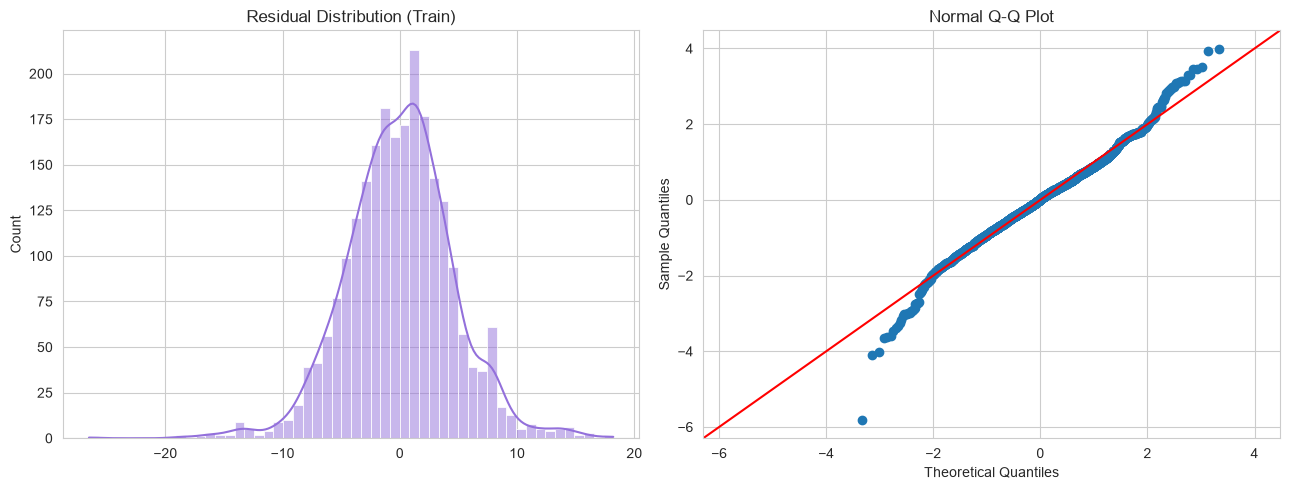

In [9]:
residuals_train = ols_model.resid

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(residuals_train, kde=True, ax=axes[0], color='mediumpurple')
axes[0].set_title('Residual Distribution (Train)')
sm.qqplot(residuals_train, line='45', fit=True, ax=axes[1])
axes[1].set_title('Normal Q-Q Plot')
plt.tight_layout()
plt.show()

In [10]:
shapiro_stat, shapiro_p = stats.shapiro(residuals_train)
print(f"Shapiro-Wilk test statistic: {shapiro_stat:.4f}")
print(f"Shapiro-Wilk p-value:        {shapiro_p:.6f}")
print(f"\nNote: with N ~ {len(residuals_train)} observations, the Central Limit Theorem ensures "
      "asymptotic normality of the OLS coefficient estimates even if residuals show mild non-normality.")

Shapiro-Wilk test statistic: 0.9874
Shapiro-Wilk p-value:        0.000000

Note: with N ~ 2342 observations, the Central Limit Theorem ensures asymptotic normality of the OLS coefficient estimates even if residuals show mild non-normality.


### 6.5 Heteroscedasticity Tests

In [11]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

# H0: Homoscedasticity (constant error variance)  |  H1: Heteroscedasticity
bp_stat, bp_p, bp_f, bp_f_p = het_breuschpagan(ols_model.resid, X_train_sm)
white_stat, white_p, white_f, white_f_p = het_white(ols_model.resid, X_train_sm)

het_results = pd.DataFrame({
    'Test': ['Breusch-Pagan', 'White'],
    'LM Statistic': [bp_stat, white_stat],
    'p-value': [bp_p, white_p]
})
print("H0: Homoscedasticity (constant variance)  vs  H1: Heteroscedasticity")
het_results

H0: Homoscedasticity (constant variance)  vs  H1: Heteroscedasticity


,Test,LM Statistic,p-value
0,Breusch-Pagan,182.067063,9.101291e-31
1,White,682.725433,8.721328e-75


In [12]:
# Robust OLS with HC3 heteroscedasticity-consistent standard errors
ols_robust = sm.OLS(y_train, X_train_sm).fit(cov_type='HC3')
print(ols_robust.summary())

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.771
Method:                 Least Squares   F-statistic:                     483.2
Date:                Sat, 22 Aug 2026   Prob (F-statistic):               0.00
Time:                        12:11:59   Log-Likelihood:                -6879.7
No. Observations:                2342   AIC:                         1.379e+04
Df Residuals:                    2326   BIC:                         1.388e+04
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

## Step 7 — Regularization & Machine Learning Benchmarking

### 7.1 Ridge Regression (L2)

In [14]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

ridge_param_grid = {'alpha': np.logspace(-3, 3, 50)}
ridge_cv = GridSearchCV(Ridge(random_state=42), ridge_param_grid, cv=5,
                         scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_cv.fit(X_train_scaled, y_train)

ridge_best = ridge_cv.best_estimator_
print(f"Best Ridge alpha: {ridge_cv.best_params_['alpha']:.5f}")

ridge_train_pred = ridge_best.predict(X_train_scaled)
ridge_test_pred = ridge_best.predict(X_test_scaled)

ridge_metrics = {
    'Train RMSE': mean_squared_error(y_train, ridge_train_pred) ** 0.5,
    'Test RMSE': mean_squared_error(y_test, ridge_test_pred) ** 0.5,
    'Train MAE': mean_absolute_error(y_train, ridge_train_pred),
    'Test MAE': mean_absolute_error(y_test, ridge_test_pred),
    'Train R2': r2_score(y_train, ridge_train_pred),
    'Test R2': r2_score(y_test, ridge_test_pred),
}
pd.Series(ridge_metrics).round(4)

Best Ridge alpha: 25.59548


Train RMSE    4.5663
Test RMSE     4.3440
Train MAE     3.4965
Test MAE      3.3590
Train R2      0.7726
Test R2       0.7818
dtype: float64

### 7.2 Lasso Regression (L1) — Sparsity

In [15]:
lasso_param_grid = {'alpha': np.logspace(-4, 2, 50)}
lasso_cv = GridSearchCV(Lasso(random_state=42, max_iter=10000), lasso_param_grid, cv=5,
                         scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_cv.fit(X_train_scaled, y_train)

lasso_best = lasso_cv.best_estimator_
print(f"Best Lasso alpha: {lasso_cv.best_params_['alpha']:.5f}")

lasso_train_pred = lasso_best.predict(X_train_scaled)
lasso_test_pred = lasso_best.predict(X_test_scaled)

lasso_metrics = {
    'Train RMSE': mean_squared_error(y_train, lasso_train_pred) ** 0.5,
    'Test RMSE': mean_squared_error(y_test, lasso_test_pred) ** 0.5,
    'Train MAE': mean_absolute_error(y_train, lasso_train_pred),
    'Test MAE': mean_absolute_error(y_test, lasso_test_pred),
    'Train R2': r2_score(y_train, lasso_train_pred),
    'Test R2': r2_score(y_test, lasso_test_pred),
}
pd.Series(lasso_metrics).round(4)

Best Lasso alpha: 0.04942


Train RMSE    4.5700
Test RMSE     4.3375
Train MAE     3.4977
Test MAE      3.3511
Train R2      0.7722
Test R2       0.7825
dtype: float64

In [16]:
# Non-zero coefficients selected by Lasso
lasso_coefs = pd.Series(lasso_best.coef_, index=X_train_scaled.columns)
nonzero_coefs = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)
print(f"Lasso retained {len(nonzero_coefs)} of {len(lasso_coefs)} features:")
nonzero_coefs

Lasso retained 13 of 15 features:


HIV/AIDS                     -3.578356
Schooling                     3.472562
Diphtheria                    1.159136
log_GDP                       1.002733
BMI                           0.973186
Polio                         0.914449
Status                        0.646869
thinness  1-19 years         -0.482245
log_percentage expenditure    0.481366
Hepatitis B                  -0.394429
log_Population               -0.361582
Measles                      -0.220843
Alcohol                      -0.040312
dtype: float64

### 7.3 Random Forest Regressor (Non-Linear Ensemble)

In [17]:
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

rf_cv = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5,
                      scoring='neg_root_mean_squared_error', n_jobs=-1)
rf_cv.fit(X_train, y_train)  # tree models don't require scaling

rf_best = rf_cv.best_estimator_
print(f"Best RF params: {rf_cv.best_params_}")

rf_train_pred = rf_best.predict(X_train)
rf_test_pred = rf_best.predict(X_test)

rf_metrics = {
    'Train RMSE': mean_squared_error(y_train, rf_train_pred) ** 0.5,
    'Test RMSE': mean_squared_error(y_test, rf_test_pred) ** 0.5,
    'Train MAE': mean_absolute_error(y_train, rf_train_pred),
    'Test MAE': mean_absolute_error(y_test, rf_test_pred),
    'Train R2': r2_score(y_train, rf_train_pred),
    'Test R2': r2_score(y_test, rf_test_pred),
}
pd.Series(rf_metrics).round(4)

Best RF params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}


Train RMSE    0.9338
Test RMSE     2.3089
Train MAE     0.6492
Test MAE      1.6664
Train R2      0.9905
Test R2       0.9384
dtype: float64

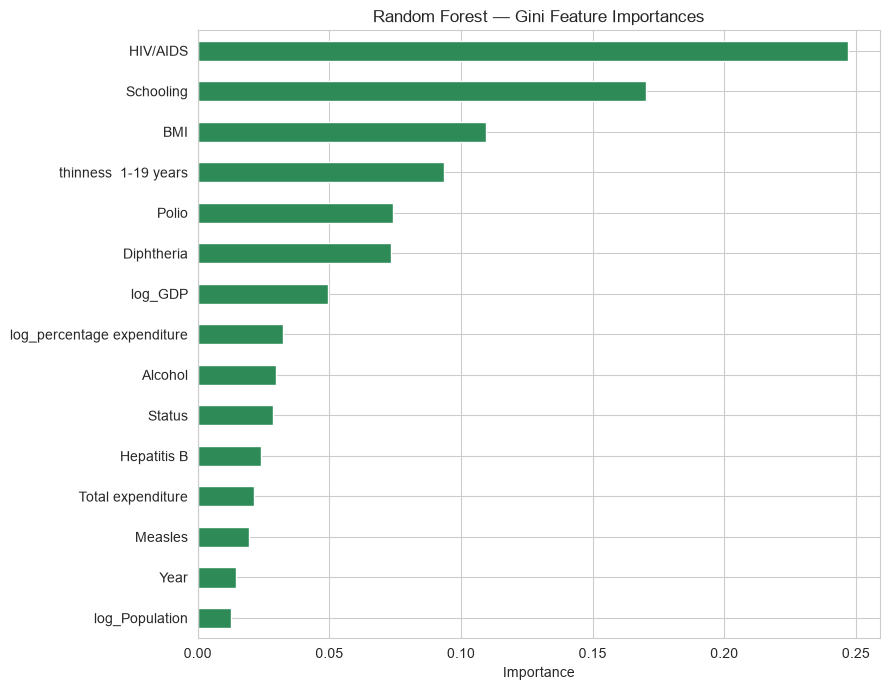

In [18]:
# Gini feature importances
importances = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(9, 7))
importances.plot(kind='barh', color='seagreen')
plt.title('Random Forest — Gini Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### 7.4 Consolidated Benchmark Table

In [19]:
ols_train_r2 = r2_score(y_train, y_train_pred)
ols_test_r2 = r2_score(y_test, y_test_pred)

benchmark = pd.DataFrame([
    {'Model': 'OLS (Statsmodels)',
     'Train RMSE': mean_squared_error(y_train, y_train_pred) ** 0.5,
     'Test RMSE': mean_squared_error(y_test, y_test_pred) ** 0.5,
     'Test MAE': mean_absolute_error(y_test, y_test_pred),
     'Train R2': ols_train_r2, 'Test R2': ols_test_r2,
     'Overfit Gap': ols_train_r2 - ols_test_r2},
    {'Model': 'Ridge',
     'Train RMSE': ridge_metrics['Train RMSE'], 'Test RMSE': ridge_metrics['Test RMSE'],
     'Test MAE': ridge_metrics['Test MAE'],
     'Train R2': ridge_metrics['Train R2'], 'Test R2': ridge_metrics['Test R2'],
     'Overfit Gap': ridge_metrics['Train R2'] - ridge_metrics['Test R2']},
    {'Model': 'Lasso',
     'Train RMSE': lasso_metrics['Train RMSE'], 'Test RMSE': lasso_metrics['Test RMSE'],
     'Test MAE': lasso_metrics['Test MAE'],
     'Train R2': lasso_metrics['Train R2'], 'Test R2': lasso_metrics['Test R2'],
     'Overfit Gap': lasso_metrics['Train R2'] - lasso_metrics['Test R2']},
    {'Model': 'Random Forest',
     'Train RMSE': rf_metrics['Train RMSE'], 'Test RMSE': rf_metrics['Test RMSE'],
     'Test MAE': rf_metrics['Test MAE'],
     'Train R2': rf_metrics['Train R2'], 'Test R2': rf_metrics['Test R2'],
     'Overfit Gap': rf_metrics['Train R2'] - rf_metrics['Test R2']},
])
benchmark.round(4)

,Model,Train RMSE,Test RMSE,Test MAE,Train R2,Test R2,Overfit Gap
0,OLS (Statsmodels),4.5659,4.3397,3.3544,0.7726,0.7823,-0.0096
1,Ridge,4.5663,4.3440,3.3590,0.7726,0.7818,-0.0093
2,Lasso,4.5700,4.3375,3.3511,0.7722,0.7825,-0.0103
3,Random Forest,0.9338,2.3089,1.6664,0.9905,0.9384,0.0521
